In [1]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay
tf.keras.utils.set_random_seed(42)

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

In [2]:
def cargar_fashion_mnist(batch_size=32, shuffle=True):
    (X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()


    X_train_full = (X_train_full[..., tf.newaxis] / 255.0).astype("float32")
    X_test = (X_test[..., tf.newaxis] / 255.0).astype("float32")


    X_train, X_valid, y_train, y_valid = train_test_split(X_train_full, y_train_full, test_size=0.1, random_state=42)


    train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
    valid_ds = tf.data.Dataset.from_tensor_slices((X_valid, y_valid))
    test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))

    if shuffle:
        train_ds = train_ds.shuffle(buffer_size=len(X_train))

    train_ds = train_ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    valid_ds = valid_ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_ds = test_ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

    return train_ds, valid_ds, test_ds

train_ds, valid_ds, test_ds = cargar_fashion_mnist()

train_ds.element_spec

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


(TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name=None),
 TensorSpec(shape=(None,), dtype=tf.uint8, name=None))

Forma del lote: (32, 28, 28, 1) | Rango: [0.00, 1.00]
Forma del lote: (32, 28, 28, 1) | Rango: [0.00, 1.00]
Forma del lote: (32, 28, 28, 1) | Rango: [0.00, 1.00]


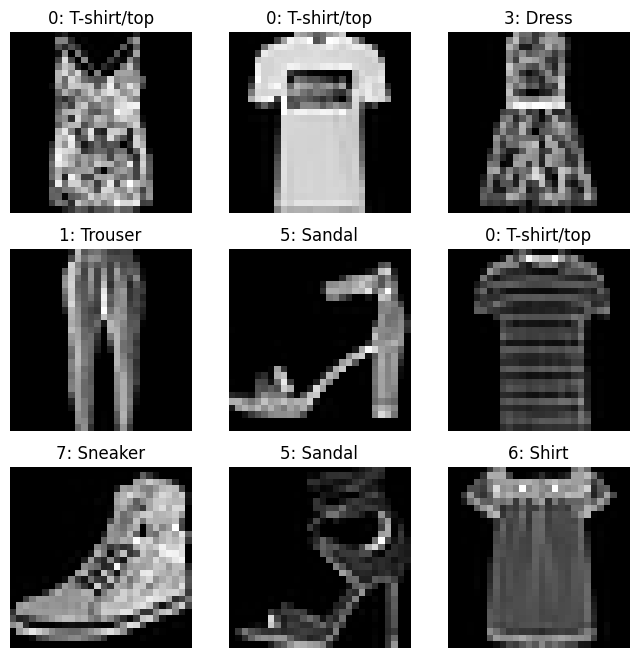

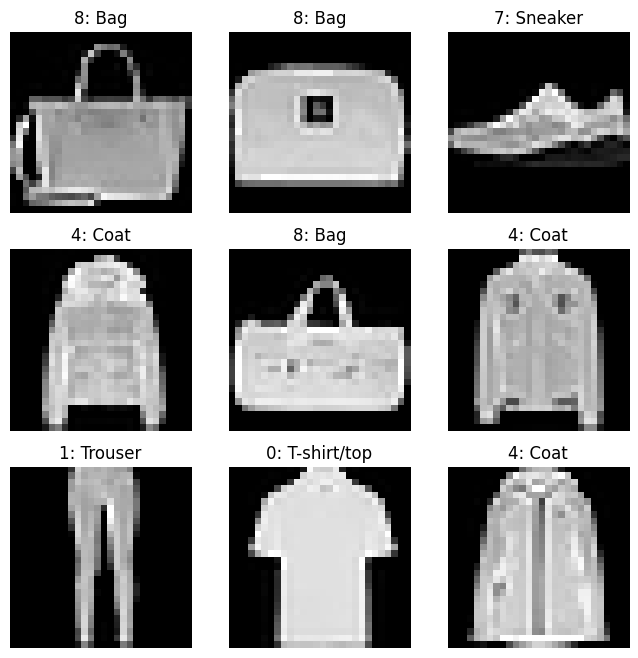

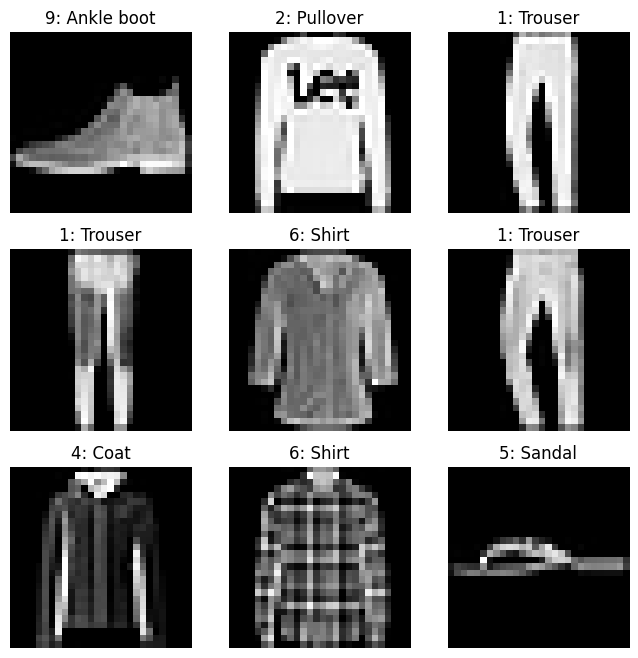

In [3]:
def imprimir_imagenes_lote(batch):
    images_batch, labels_batch = next(iter(batch))
    print(f"Forma del lote: {images_batch.shape} | Rango: [{images_batch.numpy().min():.2f}, {images_batch.numpy().max():.2f}]")
    plt.figure(figsize=(8,8))
    num_images = min(9, images_batch.shape[0])

    for i in range(num_images):
        ax = plt.subplot(3, 3, i+1)
        img = images_batch[i].numpy().squeeze()
        label_idx = int(labels_batch[i].numpy())

        plt.imshow(img, cmap='gray')
        plt.title(f"{label_idx}: {class_names[label_idx]}")
        plt.axis("off")


imprimir_imagenes_lote(train_ds.take(1))
imprimir_imagenes_lote(valid_ds.take(1))
imprimir_imagenes_lote(test_ds.take(1))

In [4]:
def construir_mlp(capas_ocultas, nombre, dropout=0.0, batchnorm=False, lr=1e-3):
    entradas = tf.keras.Input(shape=(28, 28, 1), name="imagen")
    x = tf.keras.layers.Flatten()(entradas)

    for i, unidades in enumerate(capas_ocultas):
        x = tf.keras.layers.Dense(unidades, name=f"oculta_{i+1}")(x)
        if batchnorm:
            x = tf.keras.layers.BatchNormalization(name=f"bn_{i+1}")(x)
        x = tf.keras.layers.Activation("relu")(x)
        if dropout > 0:
            x = tf.keras.layers.Dropout(dropout)(x)

    # Cuello de botella: 2 neuronas lineales -> coordenadas (z1, z2)
    z = tf.keras.layers.Dense(2, activation="linear", name="espacio_2d")(x)
    salidas = tf.keras.layers.Dense(10, activation="softmax", name="clase")(z)

    modelo = tf.keras.Model(entradas, salidas, name=nombre)
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return modelo


def entrenar(modelo, epocas=20, paciencia=3):
    # Se detiene si val_loss no mejora en `paciencia` épocas y regresa a los mejores pesos
    parada_temprana = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=paciencia, restore_best_weights=True
    )
    return modelo.fit(
        train_ds,
        validation_data=valid_ds,
        epochs=epocas,
        callbacks=[parada_temprana]
    )

In [5]:
def plot_learning_curve(history):
    # Graficar exactitud
    plt.figure()
    plt.plot(history.history['accuracy'], label='Training accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.title('accuracy Curves')
    plt.legend()
    plt.show()

    # Graficar pérdida
    plt.figure()
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss Curves')
    plt.legend()
    plt.show()


def etiquetas_de(ds):
    # Junta todas las etiquetas del dataset en un solo arreglo (el orden coincide con predict porque ds no se baraja)
    return np.concatenate([y.numpy() for _, y in ds])


def proyectar_2d(modelo, ds, ax=None):
    # Submodelo que corta la red en la capa de 2 neuronas
    codificador = tf.keras.Model(modelo.input, modelo.get_layer("espacio_2d").output)
    z = codificador.predict(ds, verbose=0)
    y = etiquetas_de(ds)

    if ax is None:
        _, ax = plt.subplots(figsize=(8, 7))
        mostrar = True
    else:
        mostrar = False

    colores = plt.cm.tab10(np.arange(10))
    for k in range(10):
        mask = y == k
        ax.scatter(z[mask, 0], z[mask, 1], s=4, alpha=0.5, color=colores[k], label=class_names[k])

    ax.set_title(f"Espacio 2D aprendido – {modelo.name}")
    ax.set_xlabel("z1")
    ax.set_ylabel("z2")
    ax.grid(linestyle="--", alpha=0.4)

    if mostrar:
        ax.legend(markerscale=4, bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.tight_layout()
        plt.show()

In [6]:
modelo_a = construir_mlp([128, 64], nombre="modelo_A_base")
modelo_a.summary()

Model: "modelo_A_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_1 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ espacio_2d (Dense)              │ (None, 2)              │           130 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clase (Dense)                   │ (None, 10)             │            30 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 108,896 (425.38 KB)

 Trainable params: 108,896 (425.38 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
history_a = entrenar(modelo_a)

Epoch 1/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.6925 - loss: 1.0152 - val_accuracy: 0.7958 - val_loss: 0.7769
Epoch 2/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8215 - loss: 0.6715 - val_accuracy: 0.8057 - val_loss: 0.6511
Epoch 3/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8384 - loss: 0.5721 - val_accuracy: 0.8322 - val_loss: 0.5868
Epoch 4/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8507 - loss: 0.5119 - val_accuracy: 0.8353 - val_loss: 0.6120
Epoch 5/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8590 - loss: 0.4754 - val_accuracy: 0.8412 - val_loss: 0.5371
Epoch 6/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8697 - loss: 0.4341 - val_accuracy: 0.8543 - val_loss: 0.5016
Epoch 7/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8847 - loss: 0.3751 - val_accuracy: 0.8680 - val_loss: 0.4724
Epoch 8/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8885 - loss: 0.3433 

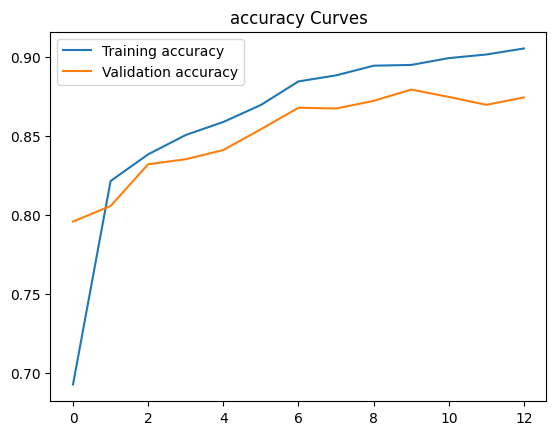

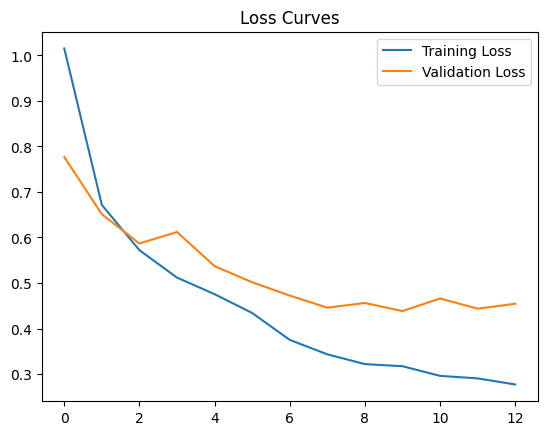

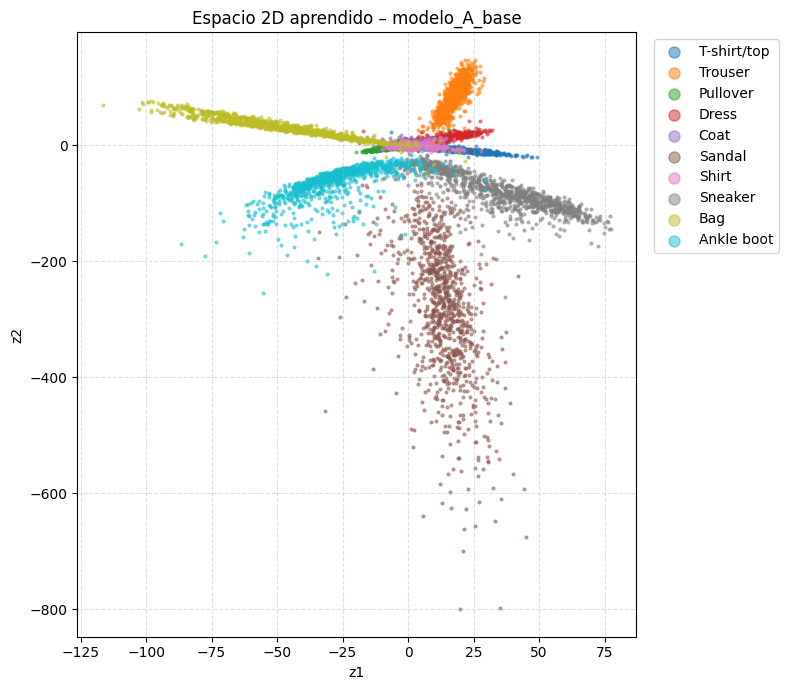

In [8]:
plot_learning_curve(history_a)
proyectar_2d(modelo_a, test_ds)

In [9]:
modelo_b = construir_mlp([256, 64, 16], nombre="modelo_B_dropout", dropout=0.2)
modelo_b.summary()

Model: "modelo_B_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_1 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_3 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ espacio_2d (Dense)              │ (None, 2)              │            34 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clase (Dense)                   │ (None, 10)             │            30 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 218,512 (853.56 KB)

 Trainable params: 218,512 (853.56 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
history_b = entrenar(modelo_b)

Epoch 1/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.6246 - loss: 1.0349 - val_accuracy: 0.7895 - val_loss: 0.6439
Epoch 2/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.7851 - loss: 0.6732 - val_accuracy: 0.8228 - val_loss: 0.5802
Epoch 3/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 19s 5ms/step - accuracy: 0.8101 - loss: 0.5965 - val_accuracy: 0.8335 - val_loss: 0.5762
Epoch 4/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8222 - loss: 0.5592 - val_accuracy: 0.8547 - val_loss: 0.4984
Epoch 5/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8298 - loss: 0.5288 - val_accuracy: 0.8522 - val_loss: 0.4809
Epoch 6/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8351 - loss: 0.5148 - val_accuracy: 0.8492 - val_loss: 0.4667
Epoch 7/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8425 - loss: 0.4878 - val_accuracy: 0.8508 - val_loss: 0.4752
Epoch 8/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8461 - loss: 0.

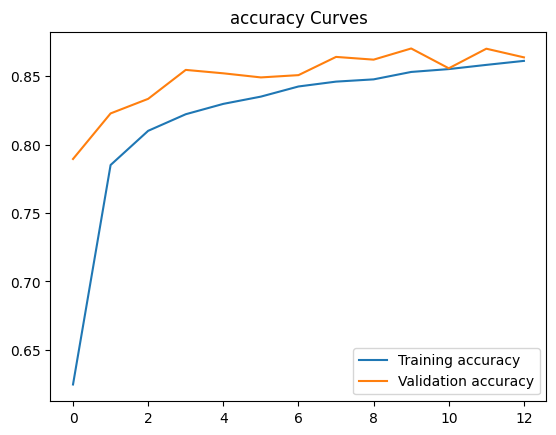

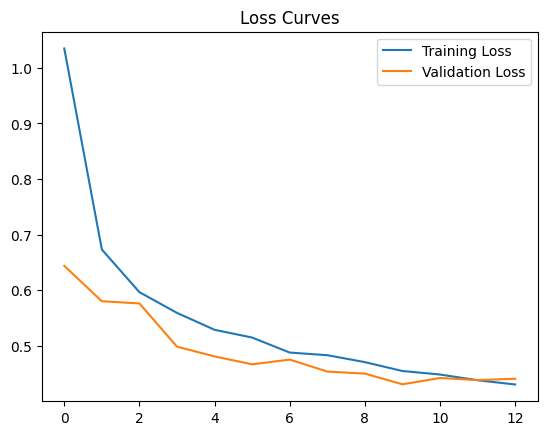

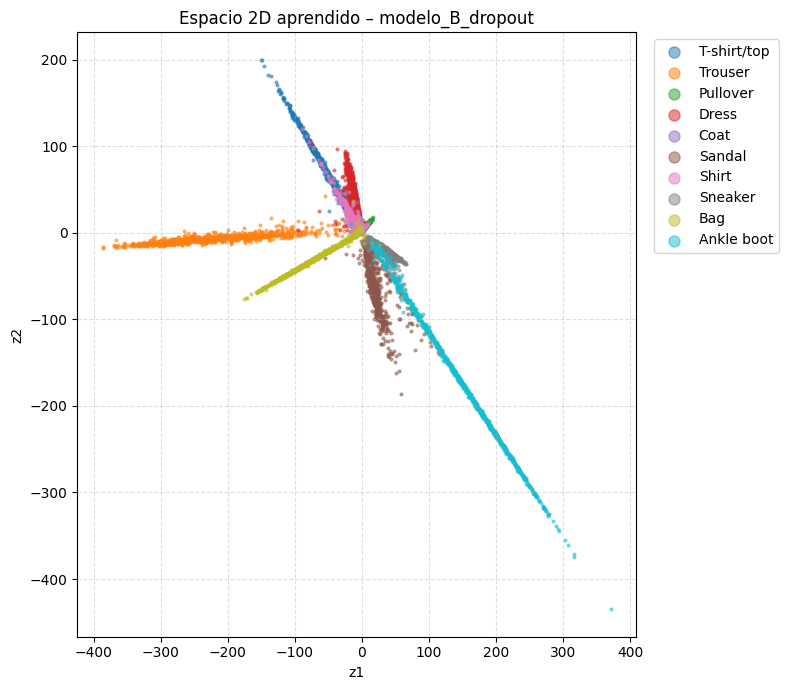

In [11]:
plot_learning_curve(history_b)
proyectar_2d(modelo_b, test_ds)

In [12]:
modelo_c = construir_mlp([256, 64, 16], nombre="modelo_C_batchnorm", batchnorm=True)
modelo_c.summary()

Model: "modelo_C_batchnorm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_1 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_3 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_3 (BatchNormalization)       │ (None, 16)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ espacio_2d (Dense)              │ (None, 2)              │            34 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clase (Dense)                   │ (None, 10)             │            30 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 219,856 (858.81 KB)

 Trainable params: 219,184 (856.19 KB)

 Non-trainable params: 672 (2.62 KB)

In [13]:
history_c = entrenar(modelo_c)

Epoch 1/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.6490 - loss: 0.9984 - val_accuracy: 0.7883 - val_loss: 0.6848
Epoch 2/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8151 - loss: 0.6043 - val_accuracy: 0.8462 - val_loss: 0.4991
Epoch 3/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8352 - loss: 0.5227 - val_accuracy: 0.8410 - val_loss: 0.4985
Epoch 4/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8486 - loss: 0.4713 - val_accuracy: 0.8447 - val_loss: 0.4793
Epoch 5/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.8580 - loss: 0.4355 - val_accuracy: 0.8545 - val_loss: 0.4482
Epoch 6/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 19s 6ms/step - accuracy: 0.8649 - loss: 0.4147 - val_accuracy: 0.8560 - val_loss: 0.4427
Epoch 7/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8718 - loss: 0.3911 - val_accuracy: 0.8553 - val_loss: 0.4431
Epoch 8/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8767 - loss: 0

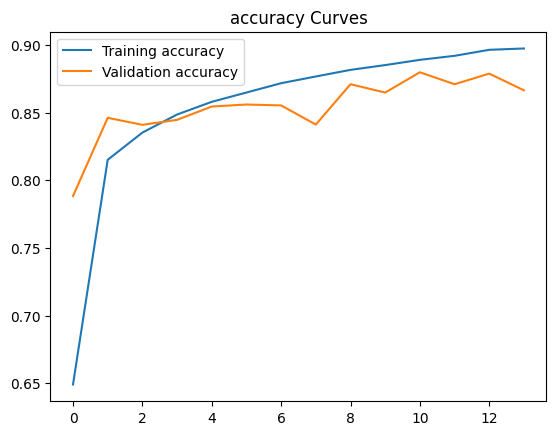

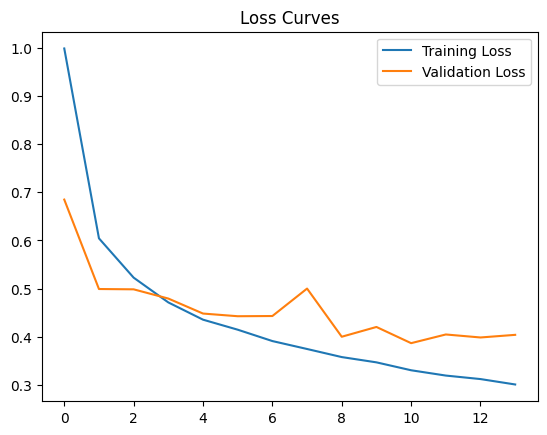

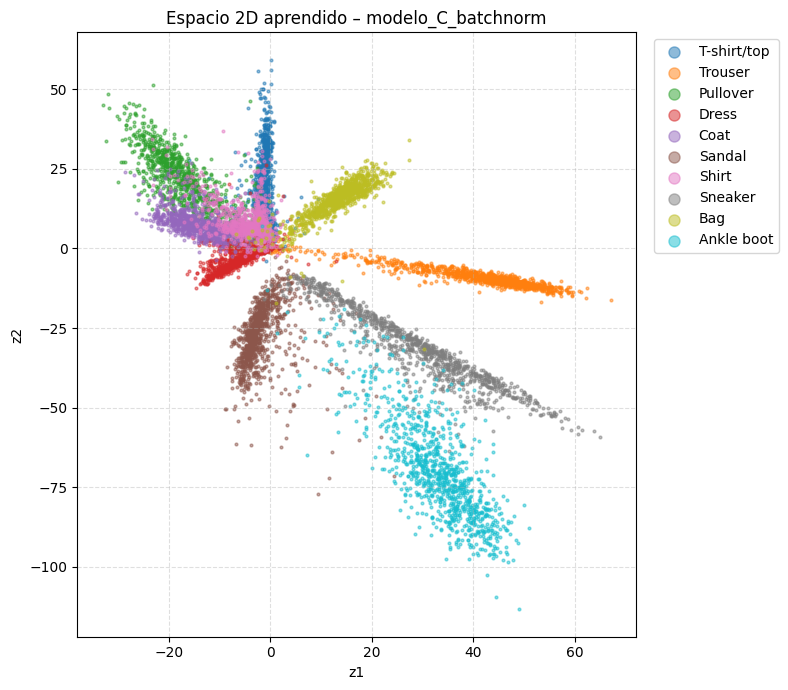

In [14]:
plot_learning_curve(history_c)
proyectar_2d(modelo_c, test_ds)

In [15]:
modelos = {"A": (modelo_a, history_a), "B": (modelo_b, history_b), "C": (modelo_c, history_c)}

filas = []
for clave, (m, h) in modelos.items():
    test_loss, test_acc = m.evaluate(test_ds, verbose=0)
    filas.append({
        "modelo": m.name,
        "parámetros": m.count_params(),
        "épocas": len(h.history["loss"]),
        "mejor val_acc": max(h.history["val_accuracy"]),
        "test_loss": test_loss,
        "test_acc": test_acc,
    })

resultados = pd.DataFrame(filas).set_index("modelo").sort_values("test_acc", ascending=False)
resultados.style.format({"mejor val_acc": "{:.4f}", "test_loss": "{:.4f}", "test_acc": "{:.4f}"})

,parámetros,épocas,mejor val_acc,test_loss,test_acc
modelo,,,,,
modelo_A_base,108896,13,0.8795,0.4542,0.8759
modelo_C_batchnorm,219856,14,0.8798,0.4091,0.8716
modelo_B_dropout,218512,13,0.8703,0.4657,0.8648


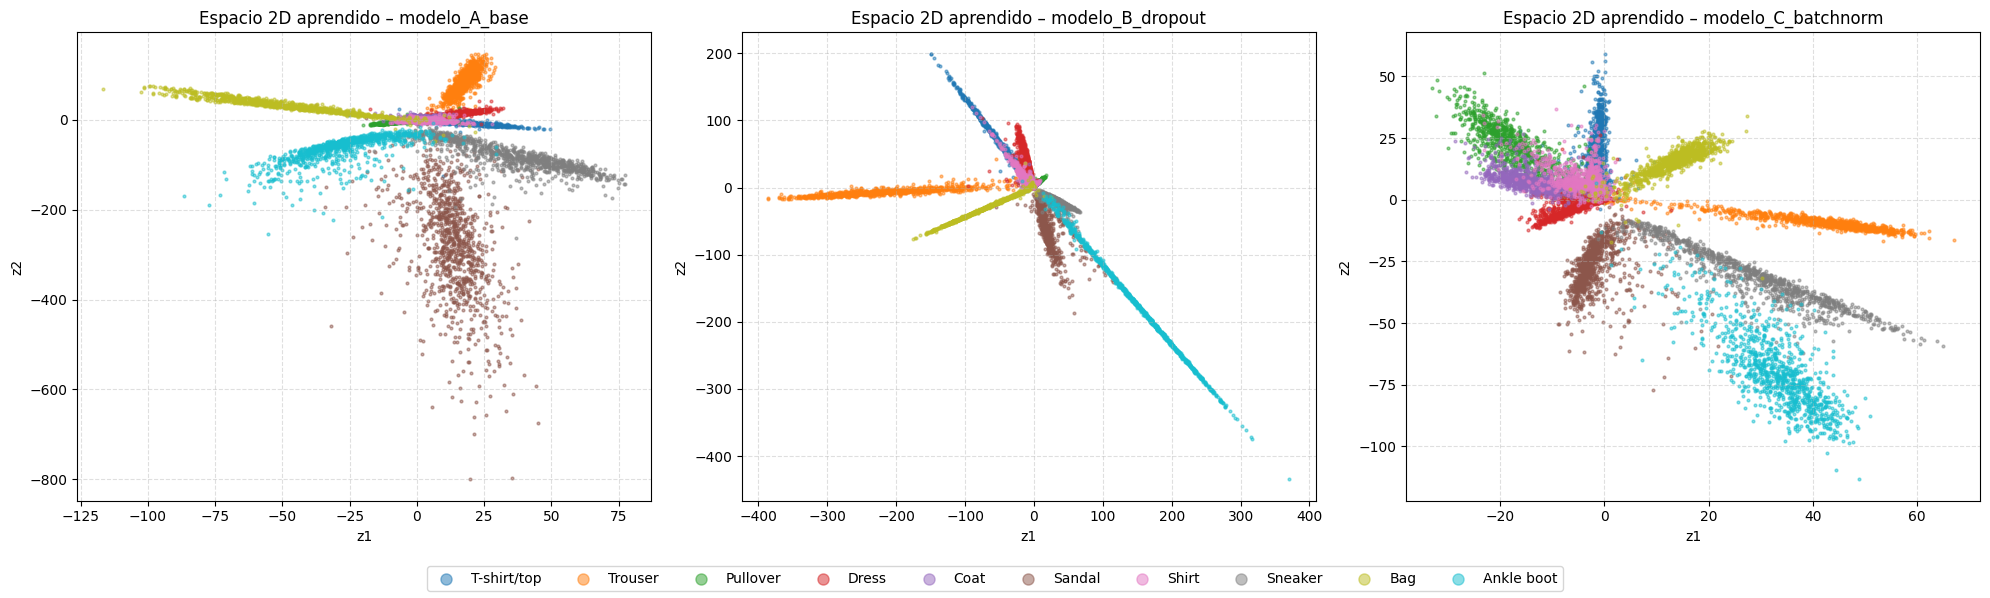

In [16]:
# Los tres espacios latentes lado a lado
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (m, _) in zip(axes, modelos.values()):
    proyectar_2d(m, test_ds, ax=ax)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=10, markerscale=4)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

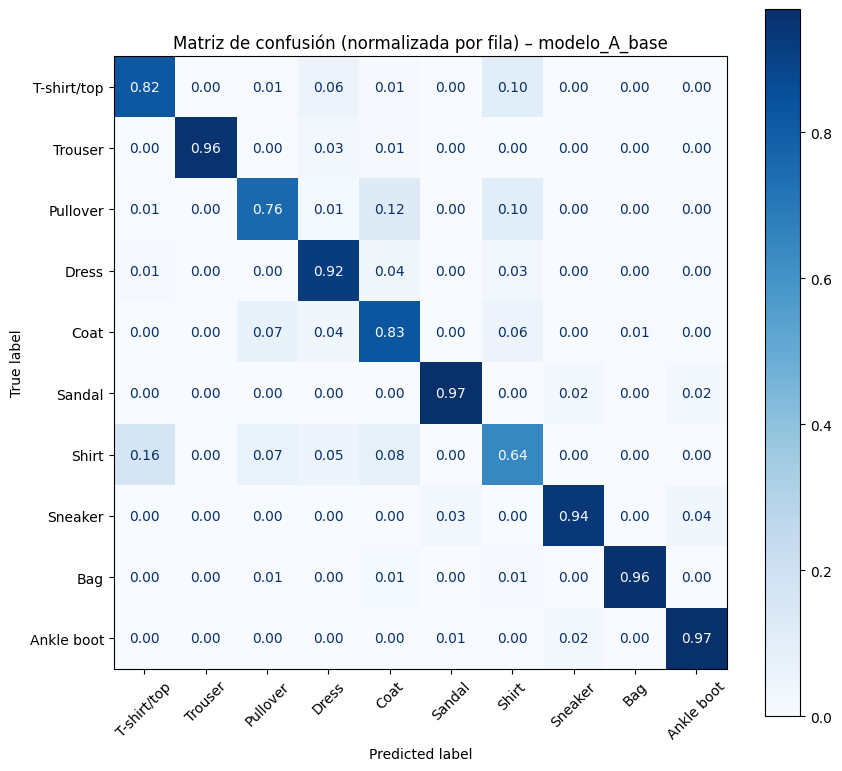

In [17]:
mejor_nombre = resultados.index[0]
mejor_modelo = next(m for m, _ in modelos.values() if m.name == mejor_nombre)

y_true = etiquetas_de(test_ds)
y_pred = np.argmax(mejor_modelo.predict(test_ds, verbose=0), axis=1)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred,
    display_labels=class_names,
    normalize="true",
    values_format=".2f",
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)
ax.set_title(f"Matriz de confusión (normalizada por fila) – {mejor_nombre}")
plt.tight_layout()
plt.show()